In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')



In [4]:
df = pd.read_csv('questions.csv')

In [5]:
df.shape[0]

404351

In [6]:
df.sample(10)

,id,qid1,qid2,question1,question2,is_duplicate
127348,127348,252288,252289,How can I make money off apps?,How do I make money with some app?,1
253476,253476,498975,498976,What's the next Google?,Which technology companies are the next Google?,0
223345,223345,440210,440211,Who are you voting for (for US president) and ...,Who are you voting for in the upcoming preside...,1
401592,401592,784505,784506,If the cost price and the selling price of an ...,What is the selling price of Google?,0
158554,158554,313519,313520,What does failure teach you?,What are your failures?,0
203527,203527,401576,401577,Which technology supports e4ebooks?,What is ASM? Is it different from ASO?,0
7716,7716,15413,15414,How can the drive from Edmonton to Auckland be...,"How do you drive from Edmonton to Auckland, an...",1
392538,392538,767207,317888,"How do you differentiate between ""lying"" and ""...",Lies and Lying: What is untruth?,0
149981,149981,296709,296710,Why does India perform so poorly at the Olympics?,Why is India not winning even a single bronze ...,1
336959,336959,660619,660620,Who according to you is the most evil superher...,Who is the most unlikable movie villain?,0


In [7]:
import re
from bs4 import BeautifulSoup

from nltk.stem import PorterStemmer
ps = PorterStemmer()

In [8]:
def preprocess(q):
    
    q = str(q).lower().strip()
    
    # Replace certain special characters with their string equivalents
    q = q.replace('%', ' percent')
    q = q.replace('$', ' dollar ')
    q = q.replace('₹', ' rupee ')
    q = q.replace('€', ' euro ')
    q = q.replace('@', ' at ')
    
    # The pattern '[math]' appears around 900 times in the whole dataset.
    q = q.replace('[math]', '')
    
    # Replacing some numbers with string equivalents
    q = q.replace(',000,000,000 ', 'b ')
    q = q.replace(',000,000 ', 'm ')
    q = q.replace(',000 ', 'k ')
    q = re.sub(r'([0-9]+)000000000', r'\1b', q)
    q = re.sub(r'([0-9]+)000000', r'\1m', q)
    q = re.sub(r'([0-9]+)000', r'\1k', q)
    
    # Decontracting words
    # https://en.wikipedia.org/wiki/Wikipedia%3aList_of_English_contractions
    # https://stackoverflow.com/a/19794953
    contractions = { 
    "ain't": "am not",
    "aren't": "are not",
    "can't": "can not",
    "can't've": "can not have",
    "'cause": "because",
    "could've": "could have",
    "couldn't": "could not",
    "couldn't've": "could not have",
    "didn't": "did not",
    "doesn't": "does not",
    "don't": "do not",
    "hadn't": "had not",
    "hadn't've": "had not have",
    "hasn't": "has not",
    "haven't": "have not",
    "he'd": "he would",
    "he'd've": "he would have",
    "he'll": "he will",
    "he'll've": "he will have",
    "he's": "he is",
    "how'd": "how did",
    "how'd'y": "how do you",
    "how'll": "how will",
    "how's": "how is",
    "i'd": "i would",
    "i'd've": "i would have",
    "i'll": "i will",
    "i'll've": "i will have",
    "i'm": "i am",
    "i've": "i have",
    "isn't": "is not",
    "it'd": "it would",
    "it'd've": "it would have",
    "it'll": "it will",
    "it'll've": "it will have",
    "it's": "it is",
    "let's": "let us",
    "ma'am": "madam",
    "mayn't": "may not",
    "might've": "might have",
    "mightn't": "might not",
    "mightn't've": "might not have",
    "must've": "must have",
    "mustn't": "must not",
    "mustn't've": "must not have",
    "needn't": "need not",
    "needn't've": "need not have",
    "o'clock": "of the clock",
    "oughtn't": "ought not",
    "oughtn't've": "ought not have",
    "shan't": "shall not",
    "sha'n't": "shall not",
    "shan't've": "shall not have",
    "she'd": "she would",
    "she'd've": "she would have",
    "she'll": "she will",
    "she'll've": "she will have",
    "she's": "she is",
    "should've": "should have",
    "shouldn't": "should not",
    "shouldn't've": "should not have",
    "so've": "so have",
    "so's": "so as",
    "that'd": "that would",
    "that'd've": "that would have",
    "that's": "that is",
    "there'd": "there would",
    "there'd've": "there would have",
    "there's": "there is",
    "they'd": "they would",
    "they'd've": "they would have",
    "they'll": "they will",
    "they'll've": "they will have",
    "they're": "they are",
    "they've": "they have",
    "to've": "to have",
    "wasn't": "was not",
    "we'd": "we would",
    "we'd've": "we would have",
    "we'll": "we will",
    "we'll've": "we will have",
    "we're": "we are",
    "we've": "we have",
    "weren't": "were not",
    "what'll": "what will",
    "what'll've": "what will have",
    "what're": "what are",
    "what's": "what is",
    "what've": "what have",
    "when's": "when is",
    "when've": "when have",
    "where'd": "where did",
    "where's": "where is",
    "where've": "where have",
    "who'll": "who will",
    "who'll've": "who will have",
    "who's": "who is",
    "who've": "who have",
    "why's": "why is",
    "why've": "why have",
    "will've": "will have",
    "won't": "will not",
    "won't've": "will not have",
    "would've": "would have",
    "wouldn't": "would not",
    "wouldn't've": "would not have",
    "y'all": "you all",
    "y'all'd": "you all would",
    "y'all'd've": "you all would have",
    "y'all're": "you all are",
    "y'all've": "you all have",
    "you'd": "you would",
    "you'd've": "you would have",
    "you'll": "you will",
    "you'll've": "you will have",
    "you're": "you are",
    "you've": "you have"
    }

    q_decontracted = []

    for word in q.split():
        if word in contractions:
            word = contractions[word] #replacing those word from existence

        q_decontracted.append(word)

    q = ' '.join(q_decontracted)
    q = q.replace("'ve", " have")
    q = q.replace("n't", " not")
    q = q.replace("'re", " are")
    q = q.replace("'ll", " will")
    
    # Removing HTML tags
    q = BeautifulSoup(q)
    q = q.get_text()
    
    # Remove punctuations
    pattern = re.compile('\W')
    q = re.sub(pattern, ' ', q).strip()

    #Stem the remaining words,
    q_stemmed = [ps.stem(word) for word in q.split()]
    q = " ".join(q_stemmed)
    
    return q
    

In [9]:
#Example
preprocess("I've already! wasn't <b>done</b>?")

'i have alreadi wa not done'

In [10]:
df['question1'] = df['question1'].apply(preprocess)
df['question2'] = df['question2'].apply(preprocess)

In [11]:
#Check point
new_df = df.copy()


In [12]:
df.head()

,id,qid1,qid2,question1,question2,is_duplicate
0,0,1,2,what is the step by step guid to invest in sha...,what is the step by step guid to invest in sha...,0
1,1,3,4,what is the stori of kohinoor koh i noor diamond,what would happen if the indian govern stole t...,0
2,2,5,6,how can i increas the speed of my internet con...,how can internet speed be increas by hack thro...,0
3,3,7,8,whi am i mental veri lone how can i solv it,find the remaind when 23 24 math is divid by 2...,0
4,4,9,10,which one dissolv in water quikli sugar salt m...,which fish would surviv in salt water,0


In [13]:
# helping functions
def common_words_cnt(row):
    w1 = set(row['question1'].split()) 
    w2 = set(row['question2'].split())    
    return len(w1 & w2) 

def total_words_cnt(row):
    w1 = set(row['question1'].split())
    w2 = set(row['question2'].split())    
    return (len(w1) + len(w2))

# Basic Extra Features 
def basic_features():
    df['q1_len'] = df['question1'].str.len() 
    df['q2_len'] = df['question2'].str.len()

    #Word counts
    df['q1_num_words'] = df['question1'].apply(lambda row: len(row.split()))
    df['q2_num_words'] = df['question2'].apply(lambda row: len(row.split()))
 
    # Common words
    df['common_words_cnt'] = df.apply(common_words_cnt, axis = 1) #applies whole each row to all rows

    # total words : q1 + q2
    df['total_words_cnt'] = df.apply(total_words_cnt, axis = 1) #applies whole each row to all rows

    # words share fraction : common / total
    df['word_share'] = (df['common_words_cnt'] / df['total_words_cnt'].replace(0, np.nan)).fillna(0).round(2) 

In [14]:
basic_features()
df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,common_words_cnt,total_words_cnt,word_share
0,0,1,2,what is the step by step guid to invest in sha...,what is the step by step guid to invest in sha...,0,64,55,14,12,11,23,0.48
1,1,3,4,what is the stori of kohinoor koh i noor diamond,what would happen if the indian govern stole t...,0,48,81,10,15,7,24,0.29
2,2,5,6,how can i increas the speed of my internet con...,how can internet speed be increas by hack thro...,0,66,52,14,10,5,24,0.21
3,3,7,8,whi am i mental veri lone how can i solv it,find the remaind when 23 24 math is divid by 2...,0,43,50,11,12,0,20,0.00
4,4,9,10,which one dissolv in water quikli sugar salt m...,which fish would surviv in salt water,0,70,37,13,7,4,20,0.20


In [15]:
# Advanced Features 
from nltk.corpus import stopwords

def fetch_token_features(row):
    q1 = row['question1']
    q2 = row['question2']
    
    SAFE_DIV = 0.0001 

    STOP_WORDS = stopwords.words("english")
    
    token_features = [0.0]*8 
    
    # Converting the Sentence into Tokens = words + stopwords: 
    q1_tokens = q1.split()
    q2_tokens = q2.split()

    # Get the common Tokens from Question pair
    common_token_count = len(set(q1_tokens).intersection(set(q2_tokens)))

    # Get the non-stopwords in Questions
    q1_words = set([word for word in q1_tokens if word not in STOP_WORDS])
    q2_words = set([word for word in q2_tokens if word not in STOP_WORDS])
    
    #Get the stopwords in Questions
    q1_stops = set([word for word in q1_tokens if word in STOP_WORDS])
    q2_stops = set([word for word in q2_tokens if word in STOP_WORDS])
    
    # Get the common non-stopwords from Question pair
    common_word_count = len(q1_words.intersection(q2_words))
    
    # Get the common stopwords from Question pair
    common_stop_count = len(q1_stops.intersection(q2_stops))
    
    
    token_features[0] = common_word_count / (min(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[1] = common_word_count / (max(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[2] = common_stop_count / (min(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[3] = common_stop_count / (max(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[4] = common_token_count / (min(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)
    token_features[5] = common_token_count / (max(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)
    
    if len(q1_tokens) > 0 and len(q2_tokens) > 0:
        token_features[6] = int(q1_tokens[-1] == q2_tokens[-1]) #Last word match
        token_features[7] = int(q1_tokens[0] == q2_tokens[0]) #first word match
    
    return token_features


In [16]:
token_features = df.apply(fetch_token_features, axis=1)

df["cwc_min"]       = list(map(lambda x: x[0], token_features))
df["cwc_max"]       = list(map(lambda x: x[1], token_features))
df["csc_min"]       = list(map(lambda x: x[2], token_features))
df["csc_max"]       = list(map(lambda x: x[3], token_features))
df["ctc_min"]       = list(map(lambda x: x[4], token_features))
df["ctc_max"]       = list(map(lambda x: x[5], token_features))
df["last_word_eq"]  = list(map(lambda x: x[6], token_features))
df["first_word_eq"] = list(map(lambda x: x[7], token_features))

In [17]:
df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,...,total_words_cnt,word_share,cwc_min,cwc_max,csc_min,csc_max,ctc_min,ctc_max,last_word_eq,first_word_eq
0,0,1,2,what is the step by step guid to invest in sha...,what is the step by step guid to invest in sha...,0,64,55,14,12,...,23,0.48,0.999980,0.833319,0.999983,0.999983,0.916659,0.785709,0.0,1.0
1,1,3,4,what is the stori of kohinoor koh i noor diamond,what would happen if the indian govern stole t...,0,48,81,10,15,...,24,0.29,0.799984,0.399996,0.749981,0.599988,0.699993,0.466664,0.0,1.0
2,2,5,6,how can i increas the speed of my internet con...,how can internet speed be increas by hack thro...,0,66,52,14,10,...,24,0.21,0.599988,0.499992,0.399992,0.249997,0.499995,0.357140,0.0,1.0
3,3,7,8,whi am i mental veri lone how can i solv it,find the remaind when 23 24 math is divid by 2...,0,43,50,11,12,...,20,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0
4,4,9,10,which one dissolv in water quikli sugar salt m...,which fish would surviv in salt water,0,70,37,13,7,...,20,0.20,0.399992,0.199998,0.999950,0.666644,0.571420,0.307690,0.0,1.0


In [18]:
import distance

def fetch_length_features(row):
    
    q1 = row['question1']
    q2 = row['question2']
    
    length_features = [0.0]*3
    
    # Converting the Sentence into Tokens: 
    q1_tokens = q1.split()
    q2_tokens = q2.split()
    
    if len(q1_tokens) == 0 or len(q2_tokens) == 0: 
        return length_features
    
    # Absolute length features
    length_features[0] = abs(len(q1_tokens) - len(q2_tokens))
    
    #Average Token Length of both Questions
    length_features[1] = (len(q1_tokens) + len(q2_tokens))/2

    # relative contiguous common string wrt the smaller q
    strs = list(distance.lcsubstrings(q1, q2)) 

    if len(strs) != 0:
        length_features[2] = len(strs[0]) / (min(len(q1), len(q2)) + 1)
    
    return length_features

In [19]:
length_features = df.apply(fetch_length_features, axis=1) 

df['abs_len_diff'] = list(map(lambda x: x[0], length_features)) 
df['mean_len'] = list(map(lambda x: x[1], length_features))
df['longest_substr_ratio'] = list(map(lambda x: x[2], length_features))

In [20]:
df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,...,cwc_max,csc_min,csc_max,ctc_min,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio
0,0,1,2,what is the step by step guid to invest in sha...,what is the step by step guid to invest in sha...,0,64,55,14,12,...,0.833319,0.999983,0.999983,0.916659,0.785709,0.0,1.0,2.0,13.0,0.982143
1,1,3,4,what is the stori of kohinoor koh i noor diamond,what would happen if the indian govern stole t...,0,48,81,10,15,...,0.399996,0.749981,0.599988,0.699993,0.466664,0.0,1.0,5.0,12.5,0.571429
2,2,5,6,how can i increas the speed of my internet con...,how can internet speed be increas by hack thro...,0,66,52,14,10,...,0.499992,0.399992,0.249997,0.499995,0.357140,0.0,1.0,4.0,12.0,0.188679
3,3,7,8,whi am i mental veri lone how can i solv it,find the remaind when 23 24 math is divid by 2...,0,43,50,11,12,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,1.0,11.5,0.045455
4,4,9,10,which one dissolv in water quikli sugar salt m...,which fish would surviv in salt water,0,70,37,13,7,...,0.199998,0.999950,0.666644,0.571420,0.307690,0.0,1.0,6.0,10.0,0.157895


In [21]:
# Fuzzy Features
from fuzzywuzzy import fuzz

def fetch_fuzzy_features(row):
    
    q1 = row['question1']
    q2 = row['question2']
    
    fuzzy_features = [0.0]*4
    
    # fuzz_ratio
    fuzzy_features[0] = fuzz.QRatio(q1, q2)

    # fuzz_partial_ratio
    fuzzy_features[1] = fuzz.partial_ratio(q1, q2)

    # token_sort_ratio
    fuzzy_features[2] = fuzz.token_sort_ratio(q1, q2)

    # token_set_ratio
    fuzzy_features[3] = fuzz.token_set_ratio(q1, q2)

    return fuzzy_features

In [22]:
fuzzy_features = df.apply(fetch_fuzzy_features, axis=1)

# Creating new feature columns for fuzzy features
df['fuzz_ratio'] = list(map(lambda x: x[0], fuzzy_features))
df['fuzz_partial_ratio'] = list(map(lambda x: x[1], fuzzy_features))
df['token_sort_ratio'] = list(map(lambda x: x[2], fuzzy_features))
df['token_set_ratio'] = list(map(lambda x: x[3], fuzzy_features))

In [23]:
print(df.shape)
df.head()

(404351, 28)


,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,...,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio,fuzz_ratio,fuzz_partial_ratio,token_sort_ratio,token_set_ratio
0,0,1,2,what is the step by step guid to invest in sha...,what is the step by step guid to invest in sha...,0,64,55,14,12,...,0.785709,0.0,1.0,2.0,13.0,0.982143,92,100,92,100
1,1,3,4,what is the stori of kohinoor koh i noor diamond,what would happen if the indian govern stole t...,0,48,81,10,15,...,0.466664,0.0,1.0,5.0,12.5,0.571429,67,71,65,86
2,2,5,6,how can i increas the speed of my internet con...,how can internet speed be increas by hack thro...,0,66,52,14,10,...,0.357140,0.0,1.0,4.0,12.0,0.188679,41,38,64,73
3,3,7,8,whi am i mental veri lone how can i solv it,find the remaind when 23 24 math is divid by 2...,0,43,50,11,12,...,0.000000,0.0,0.0,1.0,11.5,0.045455,22,26,28,31
4,4,9,10,which one dissolv in water quikli sugar salt m...,which fish would surviv in salt water,0,70,37,13,7,...,0.307690,0.0,1.0,6.0,10.0,0.157895,36,54,49,68


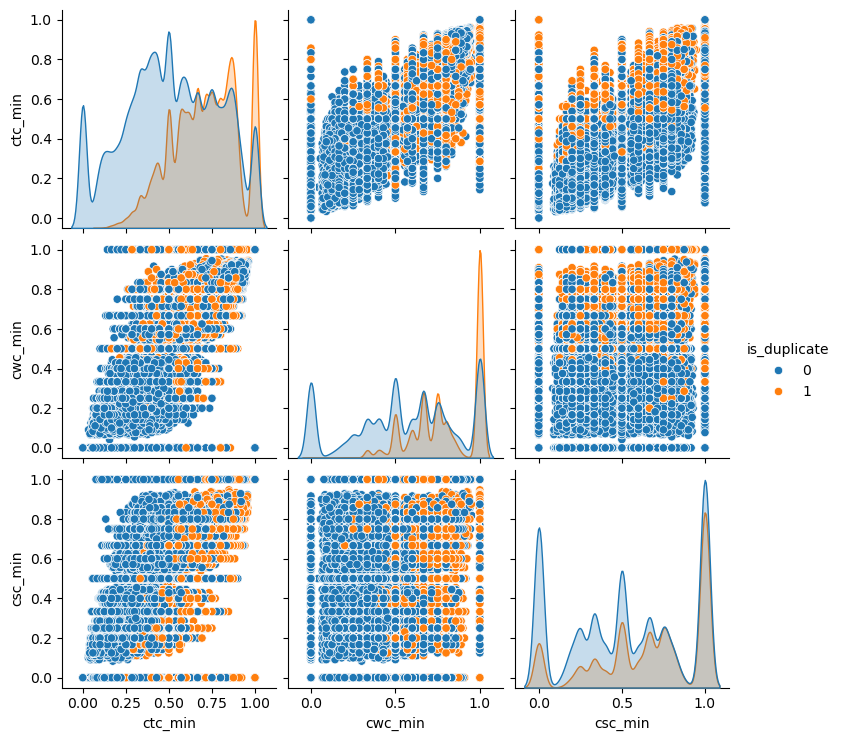

In [50]:
sns.pairplot(df[['ctc_min', 'cwc_min', 'csc_min', 'is_duplicate']],hue='is_duplicate')

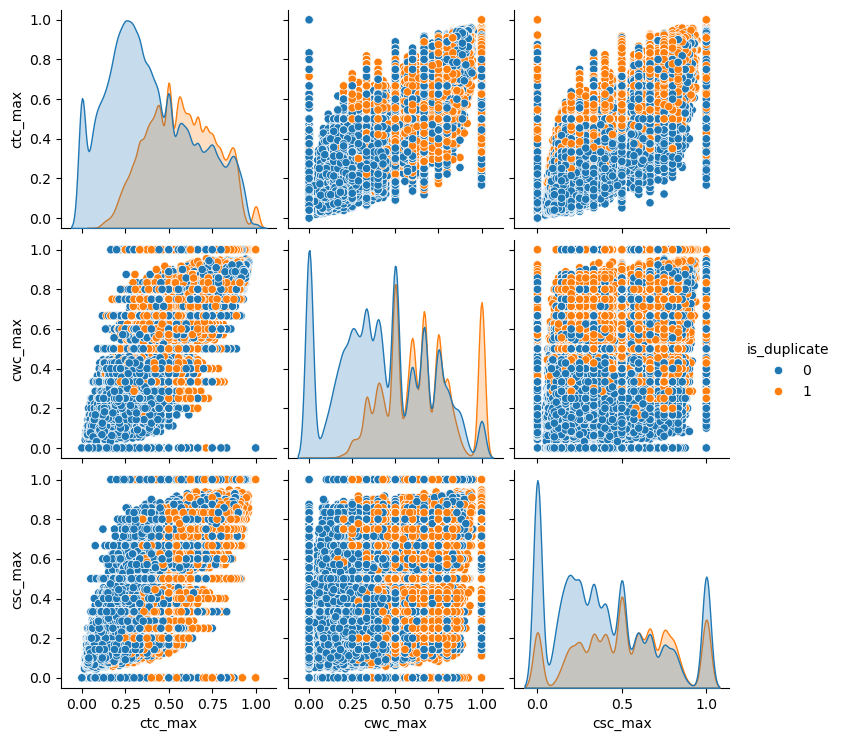

In [51]:
sns.pairplot(df[['ctc_max', 'cwc_max', 'csc_max', 'is_duplicate']],hue='is_duplicate')

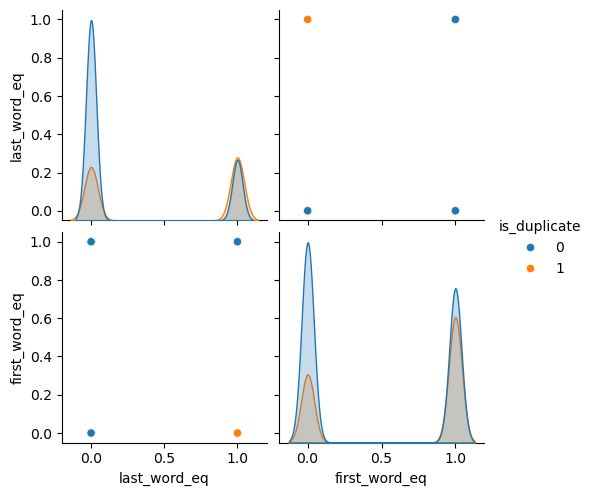

In [52]:
sns.pairplot(df[['last_word_eq', 'first_word_eq', 'is_duplicate']],hue='is_duplicate')

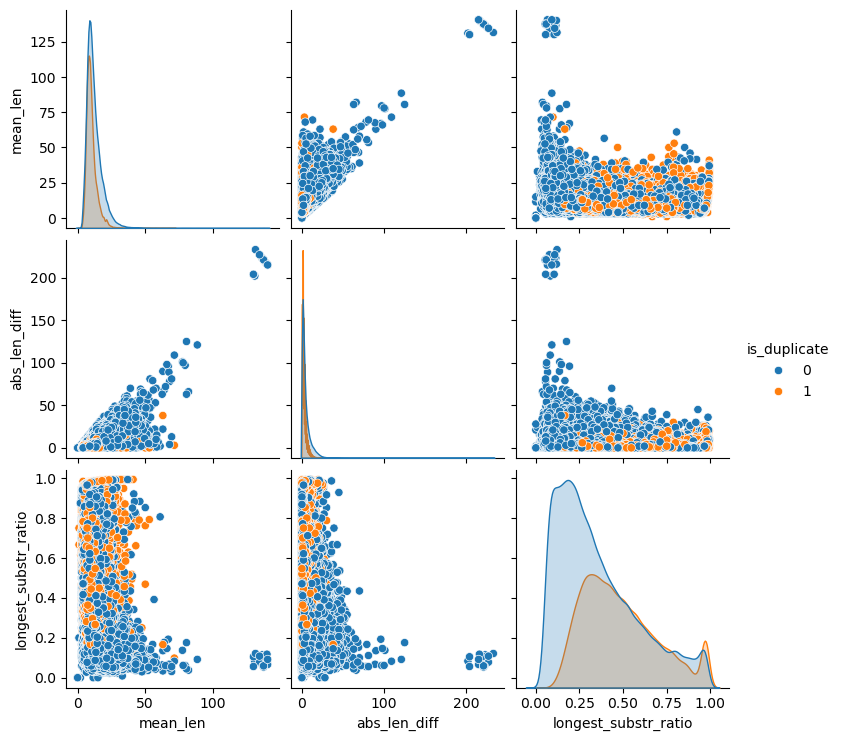

In [53]:
sns.pairplot(df[['mean_len', 'abs_len_diff','longest_substr_ratio', 'is_duplicate']],hue='is_duplicate')

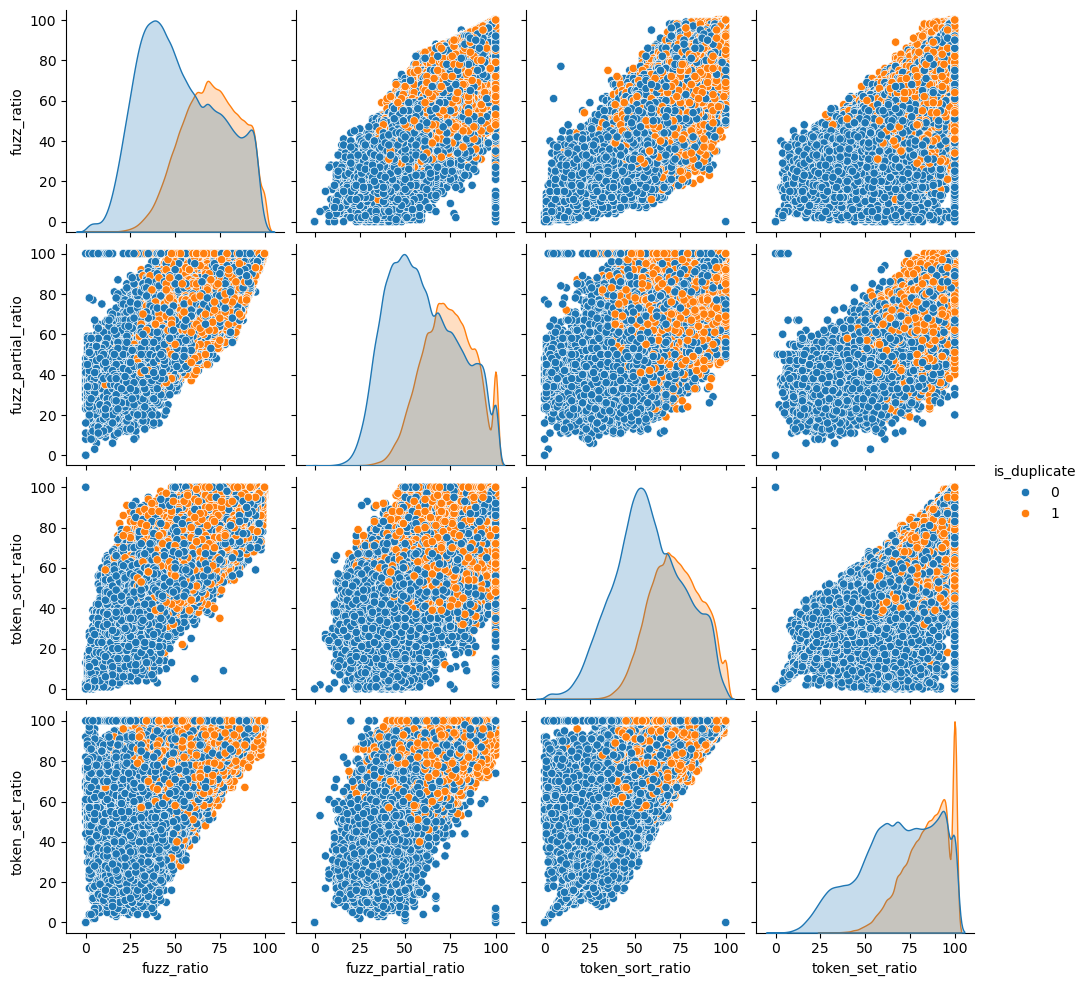

In [54]:
sns.pairplot(df[['fuzz_ratio', 'fuzz_partial_ratio','token_sort_ratio','token_set_ratio', 'is_duplicate']],hue='is_duplicate')

In [58]:
# Normalise or standardise the features for consistency while doing tsne or pca
from sklearn.preprocessing import MinMaxScaler

# Only doing for visualizing these 15 features in 2D or 3D
X = MinMaxScaler().fit_transform(df[['cwc_min', 'cwc_max', 'csc_min', 'csc_max' , 'ctc_min' , 'ctc_max' , 'last_word_eq', 'first_word_eq' , 'abs_len_diff' , 'mean_len' , 'token_set_ratio' , 'token_sort_ratio' ,  'fuzz_ratio' , 'fuzz_partial_ratio' , 'longest_substr_ratio']])
y = df['is_duplicate'].values

In [ ]:
# Using TSNE for Dimentionality reduction for 15 Features(Generated after cleaning the data) to 2 or 3 dimension
from sklearn.manifold import TSNE
tsne2d = TSNE(n_components=2, init='random', random_state=101, method='barnes_hut', n_iter=1000, verbose=0,angle=0.5).fit_transform(X)

In [ ]:
x_df = pd.DataFrame({'x':tsne2d[:,0], 'y':tsne2d[:,1] ,'label':y})
# draw the plot in appropriate place in the grid
sns.lmplot(data=x_df, x='x', y='y', hue='label', fit_reg=False, size=8,palette="Set1",markers=['s','o'])

In [24]:
final_df = df.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df.shape)
final_df.head()

(404351, 23)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,common_words_cnt,total_words_cnt,word_share,cwc_min,cwc_max,...,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio,fuzz_ratio,fuzz_partial_ratio,token_sort_ratio,token_set_ratio
0,0,64,55,14,12,11,23,0.48,0.999980,0.833319,...,0.785709,0.0,1.0,2.0,13.0,0.982143,92,100,92,100
1,0,48,81,10,15,7,24,0.29,0.799984,0.399996,...,0.466664,0.0,1.0,5.0,12.5,0.571429,67,71,65,86
2,0,66,52,14,10,5,24,0.21,0.599988,0.499992,...,0.357140,0.0,1.0,4.0,12.0,0.188679,41,38,64,73
3,0,43,50,11,12,0,20,0.00,0.000000,0.000000,...,0.000000,0.0,0.0,1.0,11.5,0.045455,22,26,28,31
4,0,70,37,13,7,4,20,0.20,0.399992,0.199998,...,0.307690,0.0,1.0,6.0,10.0,0.157895,36,54,49,68


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

# 1. Extract question columns
ques_df = df[['question1', 'question2']]

# 2. Split the question pairs into training and testing sets
train_df, test_df = train_test_split(
    ques_df,
    test_size=0.2,
    random_state=42,
    stratify=df['is_duplicate']
)

# 3. Combine training questions to learn the vocabulary and IDF values
train_questions = list(train_df['question1']) + list(train_df['question2'])

tfidf = TfidfVectorizer(max_features=3000)
tfidf.fit(train_questions)

# 4. Transform training questions into sparse TF-IDF matrices
q1_train = tfidf.transform(train_df['question1'])
q2_train = tfidf.transform(train_df['question2'])

# Horizontally combine question1 and question2 features
X_train_tfidf = hstack([q1_train, q2_train], format='csr')

# 5. Transform testing questions using the same fitted vectorizer
q1_test = tfidf.transform(test_df['question1'])
q2_test = tfidf.transform(test_df['question2'])

# Horizontally combine question1 and question2 features
X_test_tfidf = hstack([q1_test, q2_test], format='csr')



In [27]:
# 6. Extract labels using the original row indices
y_train = df.loc[train_df.index, 'is_duplicate']
y_test = df.loc[test_df.index, 'is_duplicate']

# 7. Extract the 23 engineered numerical features
X_train_num = final_df.loc[train_df.index].drop(columns=['is_duplicate'])
X_test_num = final_df.loc[test_df.index].drop(columns=['is_duplicate'])

# 9. Merge TF-IDF and numerical features
X_train = hstack([X_train_tfidf, X_train_num], format='csr')
X_test = hstack([X_test_tfidf, X_test_num], format='csr')

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model1 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model1.fit(X_train, y_train)

y_pred1 = model1.predict(X_test)

In [45]:
from xgboost import XGBClassifier

model2 = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

model2.fit(X_train, y_train)

y_pred2 = model2.predict(X_test)

In [47]:
print("Accuracy:", accuracy_score(y_test, y_pred1))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred1))
print("\nClassification Report:\n", classification_report(y_test, y_pred1))

Accuracy: 0.8296175390436621

Confusion Matrix:
 [[45063  5947]
 [ 7832 22029]]

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.88      0.87     51010
           1       0.79      0.74      0.76     29861

    accuracy                           0.83     80871
   macro avg       0.82      0.81      0.81     80871
weighted avg       0.83      0.83      0.83     80871



In [46]:
print("Accuracy:", accuracy_score(y_test, y_pred2))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred2))
print("\nClassification Report:\n", classification_report(y_test, y_pred2))

Accuracy: 0.7887252537992605

Confusion Matrix:
 [[43303  7707]
 [ 9379 20482]]

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.85      0.84     51010
           1       0.73      0.69      0.71     29861

    accuracy                           0.79     80871
   macro avg       0.77      0.77      0.77     80871
weighted avg       0.79      0.79      0.79     80871



In [48]:
def test_basic_features(q1, q2):
    w1 = set(q1.split())
    w2 = set(q2.split())

    q1_len = len(q1)
    q2_len = len(q2)

    q1_num_words = len(q1.split())
    q2_num_words = len(q2.split())

    common_words = len(w1 & w2)
    total_words = len(w1) + len(w2)

    word_share = round(common_words / total_words, 2) if total_words != 0 else 0

    return np.array([
        q1_len,
        q2_len,
        q1_num_words,
        q2_num_words,
        common_words,
        total_words,
        word_share
    ])


In [49]:
def test_fetch_token_features(q1, q2):
    SAFE_DIV = 0.0001

    STOP_WORDS = stopwords.words("english")

    token_features = [0.0] * 8

    q1_tokens = q1.split()
    q2_tokens = q2.split()

    common_token_count = len(set(q1_tokens).intersection(set(q2_tokens)))

    q1_words = set([word for word in q1_tokens if word not in STOP_WORDS])
    q2_words = set([word for word in q2_tokens if word not in STOP_WORDS])

    q1_stops = set([word for word in q1_tokens if word in STOP_WORDS])
    q2_stops = set([word for word in q2_tokens if word in STOP_WORDS])

    common_word_count = len(q1_words.intersection(q2_words))
    common_stop_count = len(q1_stops.intersection(q2_stops))

    token_features[0] = common_word_count / (min(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[1] = common_word_count / (max(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[2] = common_stop_count / (min(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[3] = common_stop_count / (max(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[4] = common_token_count / (min(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)
    token_features[5] = common_token_count / (max(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)

    if len(q1_tokens) > 0 and len(q2_tokens) > 0:
        token_features[6] = int(q1_tokens[-1] == q2_tokens[-1])
        token_features[7] = int(q1_tokens[0] == q2_tokens[0])

    return np.array(token_features)

In [50]:
def test_fetch_length_features(q1, q2):

    length_features = [0.0] * 3

    q1_tokens = q1.split()
    q2_tokens = q2.split()

    if len(q1_tokens) == 0 or len(q2_tokens) == 0:
        return np.array(length_features)

    length_features[0] = abs(len(q1_tokens) - len(q2_tokens))

    length_features[1] = (len(q1_tokens) + len(q2_tokens)) / 2

    strs = list(distance.lcsubstrings(q1, q2))

    if len(strs) != 0:
        length_features[2] = len(strs[0]) / (min(len(q1), len(q2)) + 1)

    return np.array(length_features)

In [51]:
def test_fetch_fuzzy_features(q1,q2):
    
    fuzzy_features = [0.0]*4
    
    # fuzz_ratio
    fuzzy_features[0] = fuzz.QRatio(q1, q2)

    # fuzz_partial_ratio
    fuzzy_features[1] = fuzz.partial_ratio(q1, q2)

    # token_sort_ratio
    fuzzy_features[2] = fuzz.token_sort_ratio(q1, q2)

    # token_set_ratio
    fuzzy_features[3] = fuzz.token_set_ratio(q1, q2)

    return fuzzy_features

In [56]:
def query_point_creator(q1,q2):
    
    input_query = []
    
    # preprocess
    q1 = preprocess(q1)
    q2 = preprocess(q2)
    
    # fetch basic features
    basic = test_basic_features(q1, q2)
    input_query.extend(basic)
    
    # fetch token features
    token_features = test_fetch_token_features(q1,q2)
    input_query.extend(token_features)
    
    # fetch length based features
    length_features = test_fetch_length_features(q1,q2)
    input_query.extend(length_features)
    
    # fetch fuzzy features
    fuzzy_features = test_fetch_fuzzy_features(q1,q2)
    input_query.extend(fuzzy_features)
    
    q1_tfidf = tfidf.transform([q1]).toarray() 
    q2_tfidf = tfidf.transform([q2]).toarray()
    
    
    
    return np.hstack((q1_tfidf, q2_tfidf, np.array(input_query).reshape(1,-1))) #order of features must be same as at the time of training

In [77]:
q1 = "Why is Python better than Java?"
q2 = "Why is Java better than Python?"

In [83]:
print(query_point_creator(q2,q1).shape)
model1.predict(query_point_creator(q2,q1))

(1, 6022)


array([0])

In [82]:
import pickle

pickle.dump(model1,open('model.pkl','wb'))
pickle.dump(tfidf,open('tfidf.pkl','wb'))